# Moving one design lever at a time: how three arms respond when the burden, the spacing or the powder factor changes

**Level 1: Fundamentals** · Needs: 02-classical-prediction/01-the-classical-equation-on-one-blast, 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Reading time: about 25 minutes

## Objectives

A blast engineer rarely asks for one number. The question is what happens if the burden is tightened, the spacing opened or the powder factor raised. The product answers it by perturbing one lever of a design at a time and predicting again, and it shows the response of every arm. This notebook does that for a whole campaign and three kinds of arm.

By the end you will have:

- applied the product's eight standard variants to the 22 Akdaglar blasts and predicted each with the classical equation, the published regression and a learned arm;
- matched the response curves the bake committed;
- seen which levers each arm responds to, which ones it ignores, and why.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 22 Akdaglar blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The case registry and the eight standard variants | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/cases/fragmenta_cases.py`, imported by path |
| The committed response curves | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-akdaglar/case.json`, field `variant_curves` |

A variant moves one field of a blast by a multiplier and drops the measured size, because a perturbed design has not been fired. The response is a curve of predictions, never scored against the original measurement.

## Method

For each variant `v` and each blast `b` of the case, `apply_variant(b, v)` returns a copy with one field multiplied, and the arm predicts it. The response of an arm to `v` is the mean predicted size over the case's blasts, so the spread of the campaign is carried into the curve rather than replaced by one blast. A design that stops being a blast (for example, stemming longer than the bench) is skipped by `is_degenerate`, which the product applies before any arm runs.

The pipeline module is imported by its path, because the variants are part of the product and not of the engine. The three arms are chosen to span the ladder: the classical equation (closed form on absolute geometry), the published regression (a power law on the seven ratios) and gradient boosting (a learned arm, trained here without Akdaglar).

### Step 1: the case, its variants and the arms

The cell imports the registry, lists the eight variants of the Akdaglar case and builds the three arms. The classical arm gets the engine's table of per-site rock factors, as the product's `arm_catalogue` does.

In [2]:
# Imports, the pipeline's registry by path, the case's variants and the three arms
import json
import sys
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case

DERIVED = Path("../../../data/derived")
case = get_case("real-akdaglar")
blasts = blasts_for_case(case)
print(case.title_en, "|", len(blasts), "blasts")
for variant in case.variants:
    print(f"  {variant.id:<14} {variant.field:<9} x {variant.factor:<5} {variant.label_en}")

train = bf.load_training_corpus()
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([b for b in train if b.site != case.site]),
}

Akdaglar quarry, Istanbul | 22 blasts
  base           none      x 1.0   As designed
  burden-tight   B_over_D  x 0.85  Burden 15 percent tighter
  burden-wide    B_over_D  x 1.15  Burden 15 percent wider
  spacing-wide   S_over_B  x 1.2   Spacing 20 percent wider
  powder-up      Pf_kg_m3  x 1.3   Powder factor 30 percent higher
  powder-down    Pf_kg_m3  x 0.75  Powder factor 25 percent lower
  stemming-long  T_over_B  x 1.25  Stemming 25 percent longer
  blocky         XB_m      x 1.5   In situ blocks 50 percent larger


### Step 2: the response of each arm

For each arm and variant the cell perturbs every blast of the case, skips the degenerate ones, predicts, and averages the answered predictions. It then compares each mean with the curve the bake committed.

In [3]:
# The mean predicted size per arm and variant, and the largest difference to the committed curves
artifact = json.loads((DERIVED / "real-akdaglar" / "case.json").read_text(encoding="utf-8"))
response = {}
for name, arm in arms.items():
    response[name] = {}
    for variant in case.variants:
        sizes = []
        for blast in blasts:
            perturbed = apply_variant(blast, variant)
            if is_degenerate(perturbed) is not None:
                continue
            prediction = arm.predict_one(perturbed)
            if prediction.x50_m is not None:
                sizes.append(prediction.x50_m)
        response[name][variant.id] = sum(sizes) / len(sizes)
print(f"{'variant':<16}" + "".join(f"{name:>22}" for name in arms))
for variant in case.variants:
    print(f"{variant.id:<16}" + "".join(f"{response[name][variant.id]:>22.4f}" for name in arms))
gap = max(abs(response[n][v.id] - artifact["variant_curves"][n][v.id]) for n in arms for v in case.variants)
print("largest difference to the committed curves =", f"{gap:.1e}")

variant                      kuznetsov  published-regression               xgboost
base                            0.1593                0.1795                0.2454
burden-tight                    0.1469                0.1675                0.2524
burden-wide                     0.1709                0.1905                0.2441
spacing-wide                    0.1643                0.1983                0.2402
powder-up                       0.1349                0.1742                0.2456
powder-down                     0.1912                0.1855                0.2389
stemming-long                   0.1593                0.1755                0.2528
blocky                          0.1593                0.2140                0.2672
largest difference to the committed curves = 0.0e+00


### Step 3: the change against the base design

Absolute sizes hide the lever. The cell expresses each variant as the percentage change from the base design and draws it for the three arms.

variant                      kuznetsov  published-regression               xgboost
burden-tight                     -7.8%                 -6.7%                 +2.9%
burden-wide                      +7.2%                 +6.1%                 -0.5%
spacing-wide                     +3.1%                +10.5%                 -2.1%
powder-up                       -15.3%                 -3.0%                 +0.1%
powder-down                     +20.0%                 +3.4%                 -2.6%
stemming-long                    +0.0%                 -2.2%                 +3.0%
blocky                           +0.0%                +19.2%                 +8.9%


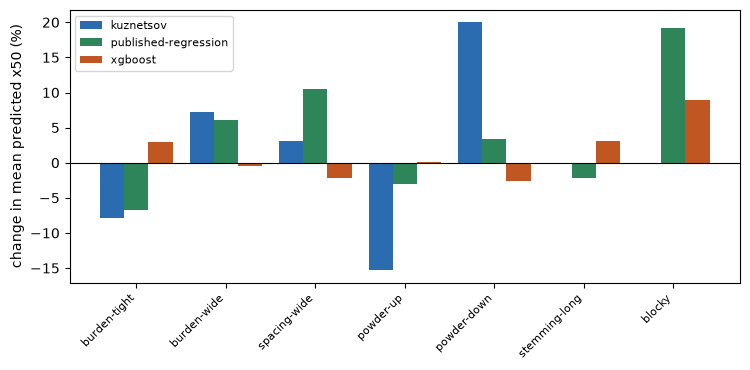

In [4]:
# Percentage change of the mean predicted size against the base design, per arm and variant
levers = [v for v in case.variants if v.id != "base"]
change = {n: [100 * (response[n][v.id] / response[n]["base"] - 1) for v in levers] for n in arms}
print(f"{'variant':<16}" + "".join(f"{name:>22}" for name in arms))
for k, variant in enumerate(levers):
    print(f"{variant.id:<16}" + "".join(f"{change[name][k]:>+21.1f}%" for name in arms))

fig, ax = plt.subplots(figsize=(7.6, 3.8))
x = np.arange(len(levers))
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
for k, name in enumerate(arms):
    ax.bar(x + (k - 1) * 0.27, change[name], 0.27, label=name, color=colors[name])
ax.set_xticks(x, [v.id for v in levers], rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("change in mean predicted x50 (%)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

**The response curves are reproducible.** The three arms' responses equal the committed curves to the rounding of the file, so the web application's design view is a replay of this calculation.

**The classical equation responds to the levers the equation contains.** A wider burden or spacing raises the predicted size, a higher powder factor lowers it, a lower one raises it. Two variants do nothing: a longer stemming and a larger in situ block change the mean size by exactly zero, because the classical equation takes the powder factor as given and has no term for either. The product shows that flat response as a finding, not as a missing bar.

**The published regression and the learned arm respond to other levers.** The regression, a power law on the seven ratios, responds to every input it contains, the stemming and the block included, with exponents that were fitted rather than derived. The learned arm responds weakly and unevenly: a tree model is piecewise constant, so a small change often falls inside one leaf and does nothing, and a larger one jumps. On this campaign it even moves against the mechanics for the burden (a tighter burden raises its prediction by a few percent) and barely moves for the powder factor, which the classical equation treats as the strongest lever.

**What this does not show.** These are model responses, not blast outcomes. No dataset records the effect of changing one lever on a given pit, so nothing here says which arm's response is right, and the product labels the curves as the response of the model.

## Summary

- A variant moves one field by a multiplier, drops the measurement and predicts again; the response of an arm is the mean over the campaign.
- The classical equation ignores the stemming and the block by construction; the regression and the learned arm respond to different levers, and a tree model responds in steps.
- The notebook reproduces the committed response curves.
- Next: notebook 02 sweeps two levers at once, the burden and the spacing, and compares the surfaces.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (the classical equation, in which the powder factor is an input)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (gradient boosting)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/